# A university compare the performance of the four study programs .

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f 

In [24]:
program_A = np.array([65,68,64,67,66])
program_B = np.array([70,72,74,71,73])
program_C = np.array([75,78,76,77,79])
program_D = np.array([80,82,84,81,83])
df = pd.DataFrame({"Program_A":program_A,"Program_B":program_B,"Program_C":program_C,"Program_D":program_D})
df


,Program_A,Program_B,Program_C,Program_D
0,65,70,75,80
1,68,72,78,82
2,64,74,76,84
3,67,71,77,81
4,66,73,79,83


In [25]:
mean_PA = df["Program_A"].mean()
mean_PB = df["Program_B"].mean()
mean_PC = df["Program_C"].mean()
mean_PD = df["Program_D"].mean()
grand_mean = df.mean().mean()
K = 4 
N = len(df)* K
dof_between = K  -1
dof_within = N - K
dof_total = dof_between + dof_within


print("mean of program A : ",mean_PA)
print("mean of progran B : ",mean_PB)
print("mean of program C : ",mean_PC)
print("mean of program D : ",mean_PD)
print("Degree of freedom between : ",dof_between)
print("Degree of freedom within  : ",dof_within)
print("Degree of freedom total : ",dof_total)


mean of program A :  66.0
mean of progran B :  72.0
mean of program C :  77.0
mean of program D :  82.0
Degree of freedom between :  3
Degree of freedom within  :  16
Degree of freedom total :  19


In [26]:
ss_between = len(df["Program_A"]) * (mean_PA - grand_mean) ** 2 + len(df["Program_B"]) * (mean_PB - grand_mean)** 2 + len(df["Program_C"]) * (mean_PC - grand_mean)**2 + len(df["Program_D"]) * (mean_PD - grand_mean) ** 2
print("sum of square between : ",ss_between)

sum of square between :  703.75


In [27]:
ss_within = ((df["Program_A"] - mean_PA)** 2) .sum() + ((df["Program_B"] - mean_PB) ** 2 ).sum() + ((df["Program_C"] - mean_PC)** 2 ).sum() + ((df["Program_D"] - mean_PD) ** 2 ).sum()
print("sum of square within : ",ss_within)

sum of square within :  40.0


In [28]:
mean_square_between = ss_between / dof_between
mean_square_within = ss_within / dof_within
f_stats = mean_square_between / mean_square_within
print("mean square between : ",mean_square_between)
print("mean square within : ",mean_square_within)
print("f test stats : ",f_stats)

mean square between :  234.58333333333334
mean square within :  2.5
f test stats :  93.83333333333334


In [29]:
alpha = 0.05
critical_value = f.ppf(1-alpha,dof_between,dof_within)
p_value = f.sf(f_stats,dof_between,dof_within)
print("Critical value : ",critical_value)
print("p value : ",p_value)


Critical value :  3.2388715174535863
p value :  2.2801987489843635e-10


In [30]:
if p_value < alpha :
    print("Decision : we reject the null hypothesis .")
    print("Conclusion : there are sufficient evidence at 5 % significance level that the four study program are different from each other .")
else:
    print("Decision : we are fail to reject the null hypothesis .")
    print("Conclusion : there are not sufficient evidence at 5 % significance level that the four study program are different from each other .")
    

Decision : we reject the null hypothesis .
Conclusion : there are sufficient evidence at 5 % significance level that the four study program are different from each other .


# visulaize the f test 

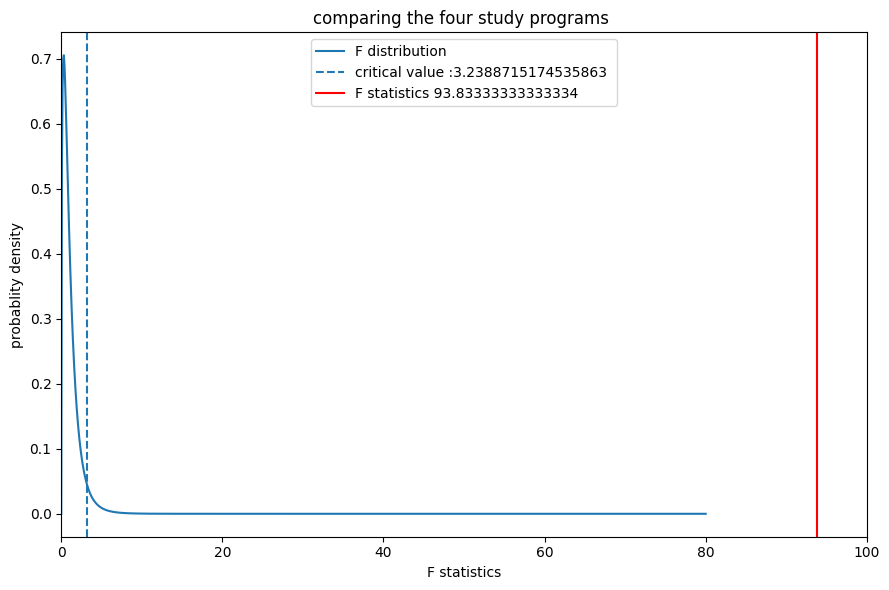

In [45]:
x = np.linspace(0,80,1000)
y = f.pdf(x,dof_between,dof_within)
plt.figure(figsize=(9,6))
plt.plot(x,y,label = "F distribution")
plt.axvline(critical_value,linestyle="--",label=f"critical value :{critical_value} ")
plt.axvline(f_stats,linestyle = "solid",color = "red",label = f"F statistics {f_stats}")
plt.xlim(0,100)
plt.title("comparing the four study programs ")
plt.xlabel("F statistics")
plt.ylabel("probablity density")
plt.legend()
plt.tight_layout()
plt.show()